# 让算法适应真实数据

In [1]:
from pathlib import Path
import sys
root = Path.cwd().resolve()
while not (root / 'lsq').is_dir():
    if root == root.parent:
        raise RuntimeError('Run inside the repository')
    root = root.parent
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import least_squares
from lsq import (finite_difference, whiten, gauss_newton,
                 levenberg_marquardt, dogleg, recursive_update)
np.set_printoptions(precision=5, suppress=True)
plt.rcParams.update({'figure.figsize': (6.4, 3.3), 'font.size': 10,
                     'axes.grid': True, 'savefig.dpi': 130})

真实数据常同时包含不同量纲、边界、异常值和错误初值。把求解器从GN换成LM通常只解决其中一部分，其他问题需要在建模和验证层处理。

## 先把参数尺度写清楚

可令$x=S z$，其中$S$是各参数典型尺度组成的对角矩阵。新雅可比为$J_z=J_xS$。这样一个单位的$z$变化，代表相近的实际重要程度。残差白化和参数缩放分别作用于行与列，含义不同，不能相互替代。

## 边界不是裁剪一下就等价

若速率必须非负，应在优化问题中明确$k\ge0$。先算无约束步再逐分量裁剪，可能破坏方向与预测下降的关系。SciPy的trf方法支持上下界；其lm方法只处理无界问题且仅支持线性损失。边界上的解也不能简单用“所有梯度为零”检查。

## 稳健损失降低异常值支配

普通平方损失会放大极端误差。以soft-L1为例，令标准化平方残差为$s$，使用$\rho(s)=2(\sqrt{1+s}-1)$。小残差附近近似平方损失，大残差处增长更慢。尺度参数应与正常噪声量级联系，而不是只为得到喜欢的答案。

truth: [2.5 0.8 0.4] ordinary: [2.57621 0.85852 0.44442] robust: [2.48872 0.7942  0.39657]


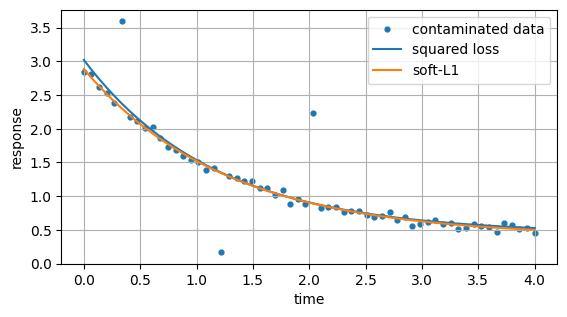

In [2]:
rng = np.random.default_rng(112)
t = np.linspace(0,4,60); sigma=.04
truth = np.array([2.5,.8,.4])
y = truth[0]*np.exp(-truth[1]*t)+truth[2]+rng.normal(0,sigma,len(t))
y[[5,18,30]] += [1.2,-1.1,1.3]
def residual(p):
    return p[0]*np.exp(-p[1]*t)+p[2]-y
bounds = ([0.,0.,0.],[6.,4.,2.])
ordinary = least_squares(residual,[2.,.5,.2],bounds=bounds,method='trf')
robust = least_squares(residual,[2.,.5,.2],bounds=bounds,
                       method='trf',loss='soft_l1',f_scale=sigma,
                       x_scale=[2.,1.,.5])
print('truth:',truth,'ordinary:',ordinary.x,'robust:',robust.x)
plt.scatter(t,y,s=12,label='contaminated data')
plt.plot(t,residual(ordinary.x)+y,label='squared loss')
plt.plot(t,residual(robust.x)+y,label='soft-L1')
plt.xlabel('time');plt.ylabel('response');plt.legend();plt.show()
assert np.all(robust.x >= np.array(bounds[0]))
assert np.all(robust.x <= np.array(bounds[1]))

稳健拟合后仍应调查异常点：设备饱和、通信错误和模型缺失是不同问题。稳健损失不会把一个错误模型自动变成正确模型，也不意味着可以不记录剔除或降权规则。

## 一个有顺序的诊断流程

先验证输入有限、单位正确、初值在边界内；再用有限差分核对雅可比；随后检查列尺度与奇异值；最后查看残差随时间、输入和预测值的结构。多初值实验可以揭示局部极小的敏感性，但不能证明已找遍所有解。

为了比较不同算法，应该统一目标定义、数据、初值和停止精度。稳健求解器的cost与普通平方损失cost定义不同，不能直接把两个数字较小的一方称为“拟合更好”。

In [3]:
starts = [[1.,.1,.1],[4.,2.,1.],[2.5,.8,.4]]
for start in starts:
    f = least_squares(residual,start,bounds=bounds,
                      loss='soft_l1',f_scale=sigma,x_scale=[2.,1.,.5])
    raw_rmse = np.sqrt(np.mean(residual(f.x)**2))
    print('start:',start,'x:',f.x,'robust cost:',f.cost,'raw RMSE:',raw_rmse)

start: [1.0, 0.1, 0.1] x: [2.48872 0.7942  0.39657] robust cost: 0.1796936775748545 raw RMSE: 0.28659395362999923
start: [4.0, 2.0, 1.0] x: [2.48872 0.7942  0.39657] robust cost: 0.1796936775748545 raw RMSE: 0.28659395362432843
start: [2.5, 0.8, 0.4] x: [2.48872 0.7942  0.39657] robust cost: 0.1796936775748545 raw RMSE: 0.2865939536366646


## 练习与解答

练习：把所有残差先除以$\sigma$，soft-L1的f_scale应怎样改？解答：若此前f_scale取$\sigma$，标准化后应取1，以保持相同的残差转折尺度。

练习：采用稳健损失后，能否直接用第05章普通最小二乘协方差公式？解答：通常不能；权重随残差变化，且可能有边界，需使用匹配的稳健协方差方法、重采样或明确的近似假设。

练习：目标不再下降时，如何区分已到噪声底与算法失败？解答：结合噪声模型、重复测量、梯度/雅可比、尺度和多初值结果判断；只有一个停止标志并不足够。